In [22]:
#Setup
import random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import torchvision.transforms.v2 as T
import torchvision.transforms.v2.functional as TF
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix

device = "cuda" if torch.cuda.is_available() else "cpu"
DATA_SEED, SHIFT_SEED = 42, 123
SEEDS = [0, 1, 2]
EPOCHS, BATCH = 60, 16
CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print(device)

cuda


In [23]:
#Data
tr = torchvision.datasets.CIFAR10('./data', train=True, download=True)
te = torchvision.datasets.CIFAR10('./data', train=False, download=True)
to_t = lambda a: torch.from_numpy(a).permute(0, 3, 1, 2).float() / 255

y_all = np.array(tr.targets)
rng = np.random.RandomState(DATA_SEED)
tr_idx, va_idx = [], []
for c in range(10):                                    # 50 per class
    idx = rng.choice(np.where(y_all == c)[0], 50, replace=False)
    tr_idx += list(idx[:40]); va_idx += list(idx[40:])  # 40 train + 10 val

Xtr, ytr = to_t(tr.data[tr_idx]), torch.tensor(y_all[tr_idx])
Xva, yva = to_t(tr.data[va_idx]), torch.tensor(y_all[va_idx])
Xcl, ycl = to_t(te.data), torch.tensor(te.targets)
print(Xtr.shape, Xva.shape, Xcl.shape)

torch.Size([400, 3, 32, 32]) torch.Size([100, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


In [24]:
#Shifted test
def hidden_corruption(x, g):
    # PLACEHOLDER: replace with the official hidden corruption when provided
    if torch.rand(1, generator=g).item() < 0.5:
        return TF.rgb_to_grayscale(x, num_output_channels=3)
    return x[[2, 1, 0]]

def make_shifted(X, seed=SHIFT_SEED, only_hidden=False):
    g = torch.Generator().manual_seed(seed)
    out = []
    for x in X:
        if not only_hidden:
            x = TF.rotate(x, (torch.rand(1, generator=g).item() * 2 - 1) * 25)
            x = TF.adjust_brightness(x, 0.5 + torch.rand(1, generator=g).item())
            x = TF.adjust_contrast(x, 0.5 + torch.rand(1, generator=g).item())
            i, j = torch.randint(0, 17, (2,), generator=g).tolist()
            x = x.clone(); x[:, i:i+16, j:j+16] = 0          # 16x16 = 25% area
        out.append(hidden_corruption(x, g).clamp(0, 1))
    return torch.stack(out)

Xsh  = make_shifted(Xcl)
Xhid = make_shifted(Xcl, only_hidden=True)
def make_known_shift(X, seed=999):
    g = torch.Generator().manual_seed(seed); out = []
    for x in X:
        x = TF.rotate(x, (torch.rand(1, generator=g).item() * 2 - 1) * 25)
        x = TF.adjust_brightness(x, 0.5 + torch.rand(1, generator=g).item())
        x = TF.adjust_contrast(x, 0.5 + torch.rand(1, generator=g).item())
        i, j = torch.randint(0, 17, (2,), generator=g).tolist()
        x = x.clone(); x[:, i:i+16, j:j+16] = 0
        out.append(x.clamp(0, 1))
    return torch.stack(out)
Xva_sh = make_known_shift(Xva)   # corrupted copy of the 100 val images only

In [25]:
#Model (Inception, <1M params)
def conv_bn(i, o, k):
    return nn.Sequential(nn.Conv2d(i, o, k, padding=k // 2, bias=False), nn.BatchNorm2d(o), nn.ReLU(True))

class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = conv_bn(cin, c1, 1)
        self.b3 = nn.Sequential(conv_bn(cin, c3r, 1), conv_bn(c3r, c3, 3))
        self.b5 = nn.Sequential(conv_bn(cin, c5r, 1), conv_bn(c5r, c5, 5))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), conv_bn(cin, cp, 1))
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer('mean', torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1))
        self.register_buffer('std',  torch.tensor([0.247, 0.243, 0.261]).view(1, 3, 1, 1))
        self.features = nn.Sequential(
           conv_bn(3, 64, 3), conv_bn(64, 128, 3), nn.MaxPool2d(2),
           Inception(128, 32, 48, 64, 16, 32, 32), nn.MaxPool2d(2),   # 160 ch
           Inception(160, 64, 64, 128, 16, 32, 32),                   # 256 ch
           nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.drop = nn.Dropout(0.3)
        self.fc = nn.Linear(256, 10)

    def forward(self, x):
        return self.fc(self.drop(self.features((x - self.mean) / self.std)))

n_params = sum(p.numel() for p in Net().parameters() if p.requires_grad)
print("Trainable parameters:", n_params); assert n_params <= 1_000_000

Trainable parameters: 251050


In [26]:
#Augmentation and training
def noise(x):   return (x + 0.05 * torch.randn_like(x)).clamp(0, 1)
def shuffle(x): return x[torch.randperm(3)]

geo = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(), T.RandomRotation(25)])
photo = T.Compose([
    T.ColorJitter(0.4, 0.4, 0.4),
    T.RandomGrayscale(0.2),
    T.RandomApply([T.Lambda(shuffle)], p=0.1),
    T.RandomApply([T.GaussianBlur(3, (0.1, 1.5))], p=0.3),
    T.RandomApply([T.Lambda(noise)], p=0.3)])
cutout = T.RandomErasing(p=0.5, scale=(0.05, 0.25), value=0)
mixer = T.RandomChoice([T.CutMix(num_classes=10), T.MixUp(num_classes=10)])

@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval()
    return torch.cat([model(X[i:i+bs].to(device)).softmax(1).cpu() for i in range(0, len(X), bs)])

def acc(model, X, y):
    return (predict(model, X).argmax(1) == y).float().mean().item() * 100

def train_run(aug, mix, ls, seed):
    set_seed(seed)
    model = Net().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)
    hist = {'loss': [], 'train': [], 'val': []}
    best_val, best_state = -1, None
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr)); total = 0
        for k in range(0, len(Xtr), BATCH):
            xb, yb = Xtr[perm[k:k+BATCH]], ytr[perm[k:k+BATCH]]
            if aug is not None:                               # on-the-fly, train only
                xb = torch.stack([aug(x) for x in xb])
            if mix and random.random() < 0.5:
                xb, yb = mixer(xb, yb)
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, label_smoothing=ls)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb)

        sched.step()
        v = 0.5 * (acc(model, Xva, yva) + acc(model, Xva_sh, yva))
        hist['loss'].append(total / len(Xtr)); hist['train'].append(acc(model, Xtr, ytr)); hist['val'].append(v)
        if v > best_val:                                      # early stopping: keep best-val epoch
            best_val = v; best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return dict(hist=hist, state=best_state, val=best_val, train=acc(model, Xtr, ytr),
                clean=acc(model, Xcl, ycl), shifted=acc(model, Xsh, ycl), hidden=acc(model, Xhid, ycl))

In [27]:
#Run all configurations (3 seeds each)
full = T.Compose([geo, photo, cutout])
configs = [
    ('No augmentation',                  None,                    False, 0.0),
    ('Geometric only',                   geo,                     False, 0.0),
    ('Photometric only',                 photo,                   False, 0.0),
    ('Geometric + photometric',          T.Compose([geo, photo]), False, 0.0),
    ('+ Cutout',                         full,                    False, 0.0),
    ('+ Mixup/CutMix + label smoothing', full,                    True,  0.1),
]
results = {}
for name, aug, mix, ls in configs:
    results[name] = [train_run(aug, mix, ls, s) for s in SEEDS]
    print("done:", name)

done: No augmentation
done: Geometric only
done: Photometric only
done: Geometric + photometric
done: + Cutout
done: + Mixup/CutMix + label smoothing


Baseline  Train: 100.00 ± 0.00 | Val: 39.50 ± 0.41 | Clean: 48.25 ± 1.06 | Shifted: 14.52 ± 0.72


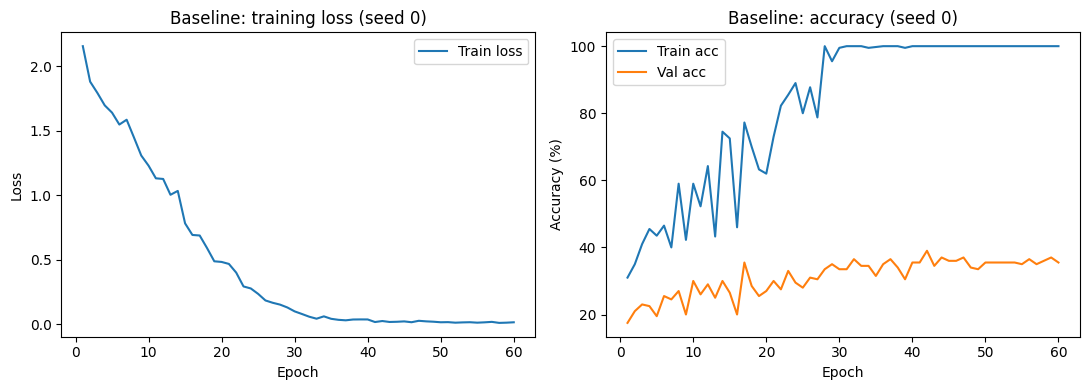

In [28]:
#Part A, Baseline
base = results['No augmentation']
ms = lambda key, r: f"{np.mean([x[key] for x in r]):.2f} ± {np.std([x[key] for x in r]):.2f}"
print("Baseline  Train:", ms('train', base), "| Val:", ms('val', base),
      "| Clean:", ms('clean', base), "| Shifted:", ms('shifted', base))

h = base[0]['hist']; ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, h['loss'], label='Train loss'); ax[0].set_title('Baseline: training loss (seed 0)')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()
ax[1].plot(ep, h['train'], label='Train acc'); ax[1].plot(ep, h['val'], label='Val acc')
ax[1].set_title('Baseline: accuracy (seed 0)'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()
plt.tight_layout(); plt.show()

In [29]:
#Part D, Ablation table
rows = []
for name, r in results.items():
    rows.append({'Configuration': name, 'Train': ms('train', r), 'Val Acc': ms('val', r),
                 'Clean Test': ms('clean', r), 'Shifted Test': ms('shifted', r), 'Hidden-only': ms('hidden', r)})
final_name = max(results, key=lambda n: np.mean([r['val'] for r in results[n]]))
print("Final model chosen by validation:", final_name)
best_row = [r for r in rows if r['Configuration'] == final_name][0]
rows.append({**best_row, 'Configuration': f'Final model (= {final_name})'})
print(pd.DataFrame(rows).to_string(index=False))

Final model chosen by validation: + Cutout
                   Configuration         Train      Val Acc   Clean Test Shifted Test  Hidden-only
                 No augmentation 100.00 ± 0.00 39.50 ± 0.41 48.25 ± 1.06 14.52 ± 0.72 39.56 ± 0.51
                  Geometric only  84.58 ± 2.16 38.67 ± 1.89 43.60 ± 1.85 16.66 ± 1.14 32.22 ± 2.50
                Photometric only  94.75 ± 7.42 42.00 ± 2.68 43.25 ± 1.86 19.78 ± 1.40 40.05 ± 1.88
         Geometric + photometric  65.58 ± 2.24 41.17 ± 0.24 44.26 ± 0.90 15.28 ± 0.73 35.60 ± 1.77
                        + Cutout  59.92 ± 1.84 47.67 ± 0.85 43.25 ± 0.41 26.94 ± 0.63 34.51 ± 0.88
+ Mixup/CutMix + label smoothing  57.92 ± 0.92 46.17 ± 0.24 41.86 ± 1.21 23.85 ± 0.65 31.68 ± 0.72
        Final model (= + Cutout)  59.92 ± 1.84 47.67 ± 0.85 43.25 ± 0.41 26.94 ± 0.63 34.51 ± 0.88


airplane     32.5%
automobile   38.0%
bird         35.4%
cat          9.1%
deer         24.5%
dog          18.7%
frog         20.2%
horse        30.9%
ship         27.9%
truck        39.3%


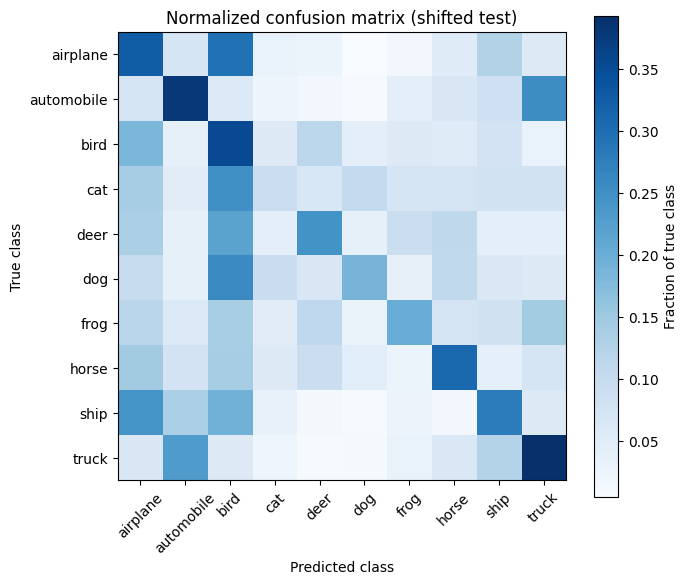

Top confusions: [(np.float64(0.295), 'airplane', 'bird'), (np.float64(0.259), 'dog', 'bird'), (np.float64(0.254), 'automobile', 'truck'), (np.float64(0.25), 'cat', 'bird'), (np.float64(0.243), 'ship', 'airplane')]


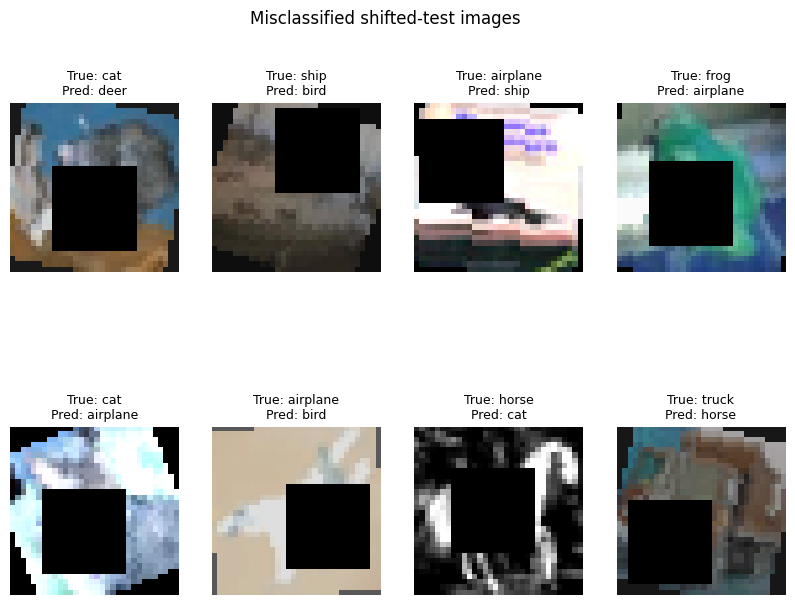

Hidden corruption only:
  No augmentation: 39.56 ± 0.51
  Final model    : 34.51 ± 0.88


In [30]:
#Part E, Error analysis
model = Net().to(device); model.load_state_dict(results[final_name][0]['state'])
pred = predict(model, Xsh).argmax(1)
cm = confusion_matrix(ycl, pred, normalize='true')

for c, a in zip(CLASSES, cm.diagonal() * 100): print(f"{c:12s} {a:.1f}%")

plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap='Blues'); cb = plt.colorbar(); cb.set_label('Fraction of true class')
plt.xticks(range(10), CLASSES, rotation=45); plt.yticks(range(10), CLASSES)
plt.xlabel('Predicted class'); plt.ylabel('True class'); plt.title('Normalized confusion matrix (shifted test)')
plt.tight_layout(); plt.show()

off = [(round(cm[i, j], 3), CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
print("Top confusions:", sorted(off, reverse=True)[:5])

wrong = torch.where(pred != ycl)[0][:8]
fig, ax = plt.subplots(2, 4, figsize=(10, 7))

for a, i in zip(ax.flat, wrong):
    a.imshow(Xsh[i].permute(1, 2, 0)); a.axis('off')
    a.set_title(f"True: {CLASSES[ycl[i]]}\nPred: {CLASSES[pred[i]]}", fontsize=9)
plt.suptitle('Misclassified shifted-test images'); plt.subplots_adjust(hspace=0.5); plt.show()

print("Hidden corruption only:")
print("  No augmentation:", ms('hidden', results['No augmentation']))
print("  Final model    :", ms('hidden', results[final_name]))

In [31]:
#Part F, TTA (bonus)
@torch.no_grad()
def tta_predict(model, X, bs=1000):
    model.eval(); shifts = [(0, 0), (2, 0), (-2, 0), (0, 2), (0, -2)]; out = []
    for i in range(0, len(X), bs):
        xb = X[i:i+bs].to(device); p = 0
        for dy, dx in shifts:
            v = torch.roll(xb, (dy, dx), (2, 3))
            p = p + model(v).softmax(1) + model(v.flip(3)).softmax(1)
        out.append((p / (2 * len(shifts))).cpu())
    return torch.cat(out)

t0 = time.time(); a0 = acc(model, Xsh, ycl); t1 = time.time()
a1 = (tta_predict(model, Xsh).argmax(1) == ycl).float().mean().item() * 100; t2 = time.time()
print(f"Shifted acc: normal {a0:.2f}% -> TTA {a1:.2f}% (change {a1 - a0:+.2f})")
print(f"Inference time: normal {t1 - t0:.1f}s, TTA {t2 - t1:.1f}s (~10x forward passes)")

Shifted acc: normal 27.65% -> TTA 27.62% (change -0.03)
Inference time: normal 1.0s, TTA 10.6s (~10x forward passes)
